# Credit Card Fraud Detection — EDA & Modeling

**Author:** Lakshman Sai Yaganti, Data Scientist @ Square

Fraud is a needle-in-a-haystack problem: only **0.173%** of the transactions in this dataset are fraudulent. This notebook explores the data, explains why accuracy is the wrong scoreboard at this imbalance, and builds two models — a logistic-regression baseline and an XGBoost classifier — comparing them on precision, recall, and PR-AUC, then tunes the decision threshold on validation data instead of trusting the default 0.5.

In [1]:
import sys
from pathlib import Path

# Make the repo's src/ package importable from the notebooks/ folder.
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 80

from src.data import load_data
from src.evaluate import compute_metrics, find_best_f1_threshold, find_threshold_for_recall
from src.features import FEATURE_COLUMNS, split_xy

RANDOM_STATE = 42
df = load_data()
print(f'{df.shape[0]:,} rows x {df.shape[1]} columns')

284,807 rows x 31 columns


## 1. Class imbalance — the whole problem in one chart

Legitimate: 284,315   Fraud: 492   Fraud rate: 0.173%
A model that predicts "legitimate" for everything scores 99.83% accuracy — and catches zero fraud.


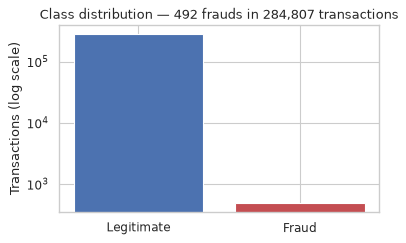

In [2]:
counts = df['Class'].value_counts().sort_index()
fraud_rate = df['Class'].mean()
print(f'Legitimate: {counts[0]:,}   Fraud: {counts[1]:,}   Fraud rate: {fraud_rate:.3%}')
print(f'A model that predicts "legitimate" for everything scores {1 - fraud_rate:.2%} accuracy — and catches zero fraud.')

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(['Legitimate', 'Fraud'], counts.values, color=['#4C72B0', '#C44E52'])
ax.set_yscale('log')
ax.set_ylabel('Transactions (log scale)')
ax.set_title('Class distribution — 492 frauds in 284,807 transactions')
plt.tight_layout()
plt.show()

## 2. Amount & Time distributions

`Amount` is the only feature with a natural unit. Fraudulent transactions skew toward smaller amounts (fraudsters test cards with small charges), and fraud is not uniformly distributed over the two days in `Time`.

          count        mean    50%       max
Class                                       
0      284315.0   88.291022  22.00  25691.16
1         492.0  122.211321   9.25   2125.87


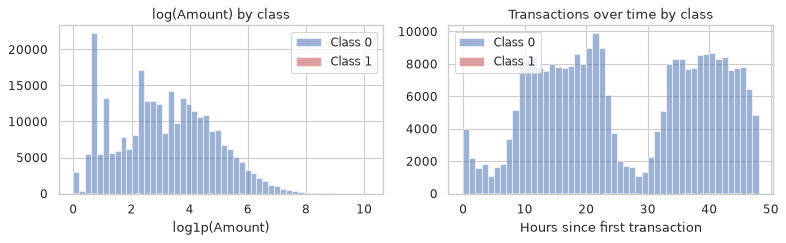

In [3]:
print(df.groupby('Class')['Amount'].describe()[['count', 'mean', '50%', 'max']])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for label, color in [(0, '#4C72B0'), (1, '#C44E52')]:
    subset = df[df['Class'] == label]
    axes[0].hist(np.log1p(subset['Amount']), bins=50, alpha=0.55, label=f'Class {label}', color=color)
    axes[1].hist(subset['Time'] / 3600, bins=48, alpha=0.55, label=f'Class {label}', color=color)
axes[0].set_title('log(Amount) by class'); axes[0].set_xlabel('log1p(Amount)'); axes[0].legend()
axes[1].set_title('Transactions over time by class'); axes[1].set_xlabel('Hours since first transaction'); axes[1].legend()
plt.tight_layout()
plt.show()

## 3. Which features separate fraud from legitimate?

The V-features are PCA components, so individual meanings are hidden — but their correlation with the target still shows which components carry the fraud signal.

Top correlations with Class:
V17   -0.326
V14   -0.303
V12   -0.261
V10   -0.217
V16   -0.197
V3    -0.193
V7    -0.187
V11    0.155
V4     0.133
V18   -0.111
Name: Class, dtype: float64


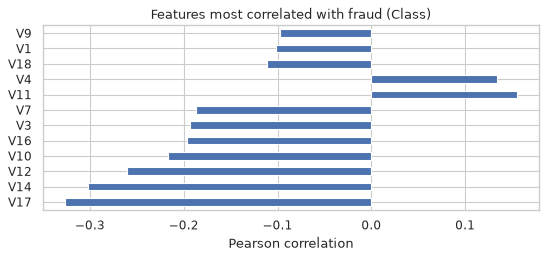

In [4]:
corr = df[FEATURE_COLUMNS + ['Class']].corr()['Class'].drop('Class').sort_values(key=abs, ascending=False)
print('Top correlations with Class:')
print(corr.head(10).round(3))

fig, ax = plt.subplots(figsize=(7, 3.4))
corr.head(12).plot.barh(ax=ax, color='#4C72B0')
ax.set_title('Features most correlated with fraud (Class)')
ax.set_xlabel('Pearson correlation')
plt.tight_layout()
plt.show()

## 4. Modeling setup

Stratified **70/15/15 train/validation/test** split. The validation split has one job: choose the decision threshold. The test split is touched only for final reporting. Preprocessing robust-scales `Time`/`Amount` and passes the PCA features through (see `src/features.py`).

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from src.features import build_preprocessor

X, y = split_xy(df)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)
print(f'Train {len(X_train):,} | Val {len(X_val):,} | Test {len(X_test):,}')

scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())
print(f'scale_pos_weight (neg/pos in train): {scale_pos_weight:.1f}')

baseline = Pipeline([('prep', build_preprocessor()),
                     ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE))])
xgb = Pipeline([('prep', build_preprocessor()),
                ('clf', XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.9,
                                      colsample_bytree=0.9, scale_pos_weight=scale_pos_weight,
                                      tree_method='hist', eval_metric='aucpr', random_state=RANDOM_STATE, n_jobs=-1))])

baseline.fit(X_train, y_train)
xgb.fit(X_train, y_train)
print('Both models trained.')

Train 199,364 | Val 42,721 | Test 42,722
scale_pos_weight (neg/pos in train): 578.5


Both models trained.


## 5. Results at the default 0.5 threshold

In [6]:
rows = {}
for name, model in [('Logistic Regression', baseline), ('XGBoost', xgb)]:
    prob = model.predict_proba(X_test)[:, 1]
    m = compute_metrics(y_test, prob, threshold=0.5)
    rows[name] = {k: m[k] for k in ['precision', 'recall', 'f1', 'roc_auc', 'pr_auc']}
results = pd.DataFrame(rows).T
results

,precision,recall,f1,roc_auc,pr_auc
Logistic Regression,0.0669,0.8784,0.1243,0.9677,0.7923
XGBoost,0.8955,0.8108,0.8511,0.9686,0.8402


## 6. Precision–recall curve and threshold choice

With fraud this rare, the PR curve matters more than ROC: a model can hold a 0.99 ROC-AUC while still flooding analysts with false alarms. The threshold is chosen on **validation** data by maximizing F1, then frozen for the test set.

Best-F1 threshold (validation): 0.2916  (validation F1 = 0.841)
Threshold for ~90% recall (validation): 0.0000  (validation precision = 0.032)


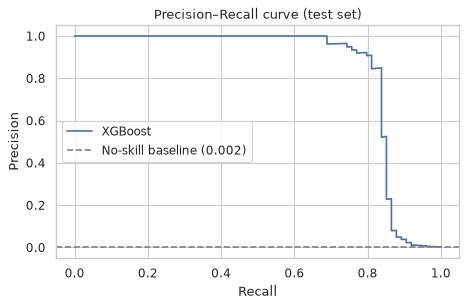

In [7]:
from sklearn.metrics import precision_recall_curve

val_prob = xgb.predict_proba(X_val)[:, 1]
test_prob = xgb.predict_proba(X_test)[:, 1]

best_threshold, best_val_f1 = find_best_f1_threshold(y_val, val_prob)
recall90_threshold, recall90_precision = find_threshold_for_recall(y_val, val_prob, target_recall=0.90)
print(f'Best-F1 threshold (validation): {best_threshold:.4f}  (validation F1 = {best_val_f1:.3f})')
print(f'Threshold for ~90% recall (validation): {recall90_threshold:.4f}  (validation precision = {recall90_precision:.3f})')

prec, rec, _ = precision_recall_curve(y_test, test_prob)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rec, prec, color='#4C72B0', label='XGBoost')
ax.axhline(y_test.mean(), color='grey', linestyle='--', label=f'No-skill baseline ({y_test.mean():.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision–Recall curve (test set)')
ax.legend()
plt.tight_layout()
plt.show()

XGBoost on test @ validation-chosen threshold:
{'threshold': 0.2916, 'precision': 0.8571, 'recall': 0.8108, 'f1': 0.8333, 'pr_auc': 0.8402}
Confusion matrix: {'tn': 42638, 'fp': 10, 'fn': 14, 'tp': 60}


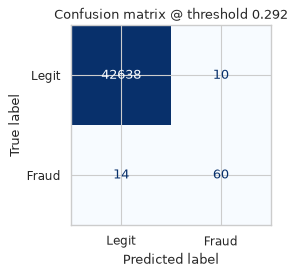

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay

tuned = compute_metrics(y_test, test_prob, threshold=best_threshold)
print('XGBoost on test @ validation-chosen threshold:')
print({k: tuned[k] for k in ['threshold', 'precision', 'recall', 'f1', 'pr_auc']})
print('Confusion matrix:', tuned['confusion_matrix'])

fig, ax = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay.from_predictions(y_test, (test_prob >= best_threshold).astype(int),
                                        display_labels=['Legit', 'Fraud'], cmap='Blues', ax=ax, colorbar=False)
ax.set_title(f'Confusion matrix @ threshold {best_threshold:.3f}')
plt.tight_layout()
plt.show()

## 7. What drives the model? (SHAP)

SHAP values on a sample of the test set show which PCA components push a transaction toward a fraud score — the same kind of explanation an analyst needs before blocking a real customer's card.

/home/hatch/workspace/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


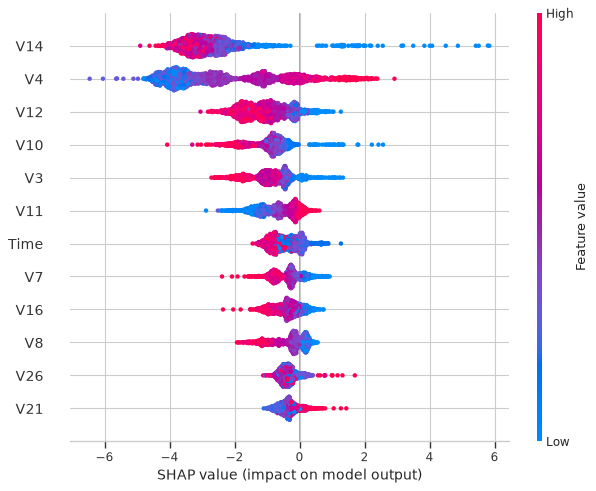

In [9]:
import shap

sample = X_test.sample(n=2000, random_state=RANDOM_STATE)
sample_prep = pd.DataFrame(xgb.named_steps['prep'].transform(sample), columns=FEATURE_COLUMNS)
explainer = shap.TreeExplainer(xgb.named_steps['clf'])
shap_values = explainer.shap_values(sample_prep)
shap.summary_plot(shap_values, sample_prep, max_display=12, show=False)
plt.tight_layout()
plt.show()

## 8. Conclusion

- **Accuracy is a trap** at 0.173% fraud: the no-skill model scores 99.83% and stops nothing.
- **XGBoost >> logistic regression** on PR-AUC — gradient boosting captures the non-linear interactions between PCA components that a linear model misses.
- **The threshold is a business decision**, not a default — and with only ~74 frauds per split it is a *noisy* estimate: a threshold that maximizes F1 on validation does not always beat 0.5 on test. In production you would set it from the cost ratio (a missed fraud vs. an analyst review) and re-estimate it on far more data; the ~90%-recall threshold above shows the precision cost of catching almost everything.
- **In production** (see `api/app.py`) this model scores transactions through FastAPI with the validation-chosen threshold, and the natural next steps are drift monitoring, periodic retraining, and per-segment threshold analysis.
